# Predictive analytics


<h3>Imports & Plotting Configuration</h3>

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ML & Feature Extraction imports
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Setup complete for Unit III Predictive Machine Learning!")

Setup complete for Unit III Predictive Machine Learning!


<h3>Load Enriched Dataset </h3>

In [3]:
data_path = '../data/processed/cleaned_reviews_sentiment.csv'
if not os.path.exists(data_path):
    data_path = '../data/processed/cleaned_reviews.csv'

df = pd.read_csv(data_path, dtype={'product_name': str})


In [11]:
print(df.isnull().sum())

product_id               0
product_name          6759
brand                    0
category                 0
rating                   0
review_text              0
title                    0
recommended_raw        560
helpful_votes            0
recommended_ind          0
recommended_label        0
review_char_count        0
review_word_count        0
has_title                0
polarity                 0
subjectivity             0
sentiment_category       0
dtype: int64


<h3>Feature Matrix Assembly</h3>

In [10]:
# Feature Extraction: TF-IDF Text Vectorization
# Converts raw review text into numerical values representing Term Frequency-Inverse Document Frequency 
#(evaluates how important a word is to a document relative to the entire dataset)

tfidf = TfidfVectorizer(max_features=300, stop_words='english') #instance 
X_text = tfidf.fit_transform(df['review_text']).toarray()  # fit.transform(train a model)

# Numeric & Metric Features
numeric_cols  = ['rating', 'review_char_count', 'review_word_count', 'has_title','polarity', 'subjectivity']
X_num = df[numeric_cols].fillna(0).values

In [15]:
X = np.hstack((X_num, X_text)) #Concatenates the numerical and text features horizontally into a single 2D NumPy array
y = df['recommended_ind'].values

print(f"Dataset sampled to {len(df):,} rows.")
print(f"Feature Matrix Shape: {X.shape} (Numeric + TF-IDF terms)")
print(f"Class Distribution: Churned/Not Rec: {np.bincount(y)[0]} Retained/Rec :{np.bincount(y)[1]} ")

Dataset sampled to 34,626 rows.
Feature Matrix Shape: (34626, 306) (Numeric + TF-IDF terms)
Class Distribution: Churned/Not Rec: 1487 Retained/Rec :33139 


<h3>Train-Test Split & Feature Scaling</h3>

In [16]:
# Train (80%) / Test (20%) Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
) # stratify=y ensures that the split preserves the exact same class distribution (proportion of target labels)

# Standardize numerical and TF-IDF features for distance/gradient-based models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Set Shape : {X_train_scaled.shape}")
print(f"Testing Set Shape  : {X_test_scaled.shape}")

Training Set Shape : (27700, 306)
Testing Set Shape  : (6926, 306)


<h3>Train & Evaluate</h3>
K-Nearest Neighbors (KNN)<br>
Support Vector Machines (SVM)<br>
Neural Networks (MLP)

In [17]:
models = {
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),
    'Support Vector Machines (SVM)': SVC(kernel='rbf', probability=True, random_state=42),
    'Neural Networks (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, random_state=42)
}

results = {}
os.makedirs('../models', exist_ok=True)

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    results[name] = {
        'model': model,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'roc_auc': auc,
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    
    # Save trained model object
    model_filename = f"../models/{name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.pkl"
    joblib.dump(model, model_filename)
    print(f" Saved model to {model_filename}")

print("\nModel training complete!")

Training K-Nearest Neighbors (KNN)...
 Saved model to ../models/k-nearest_neighbors_knn.pkl
Training Support Vector Machines (SVM)...


C:\Users\shubh\python_ecommerce-customer-analytics\Ecom_venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


 Saved model to ../models/support_vector_machines_svm.pkl
Training Neural Networks (MLP)...
 Saved model to ../models/neural_networks_mlp.pkl

Model training complete!


<h3>Model Performance Comparison Summary</h3>


In [26]:
# Performance Summary DataFrame
summary_df = pd.DataFrame({
    'Algorithm': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results],
    'Precision': [results[m]['precision'] for m in results],
    'Recall': [results[m]['recall'] for m in results],
    'F1 Score': [results[m]['f1'] for m in results],
    'ROC-AUC': [results[m]['roc_auc'] for m in results]
}).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

print("==========================================================================")
print("                    MACHINE LEARNING BENCHMARK SUMMARY                    ")
print("==========================================================================")
display(summary_df.style.background_gradient(cmap='YlOrBr')) #'YlOrBr' (Yellow to Orange to Brown)

                    MACHINE LEARNING BENCHMARK SUMMARY                    


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Support Vector Machines (SVM),0.974300,0.976089,0.997586,0.986720,0.968002
1,Neural Networks (MLP),0.975599,0.983099,0.991552,0.987308,0.959439
2,K-Nearest Neighbors (KNN),0.958129,0.959015,0.998944,0.978572,0.736707


<h3>Confusion Matrices & ROC-AUC Curve Visualizations</h3>

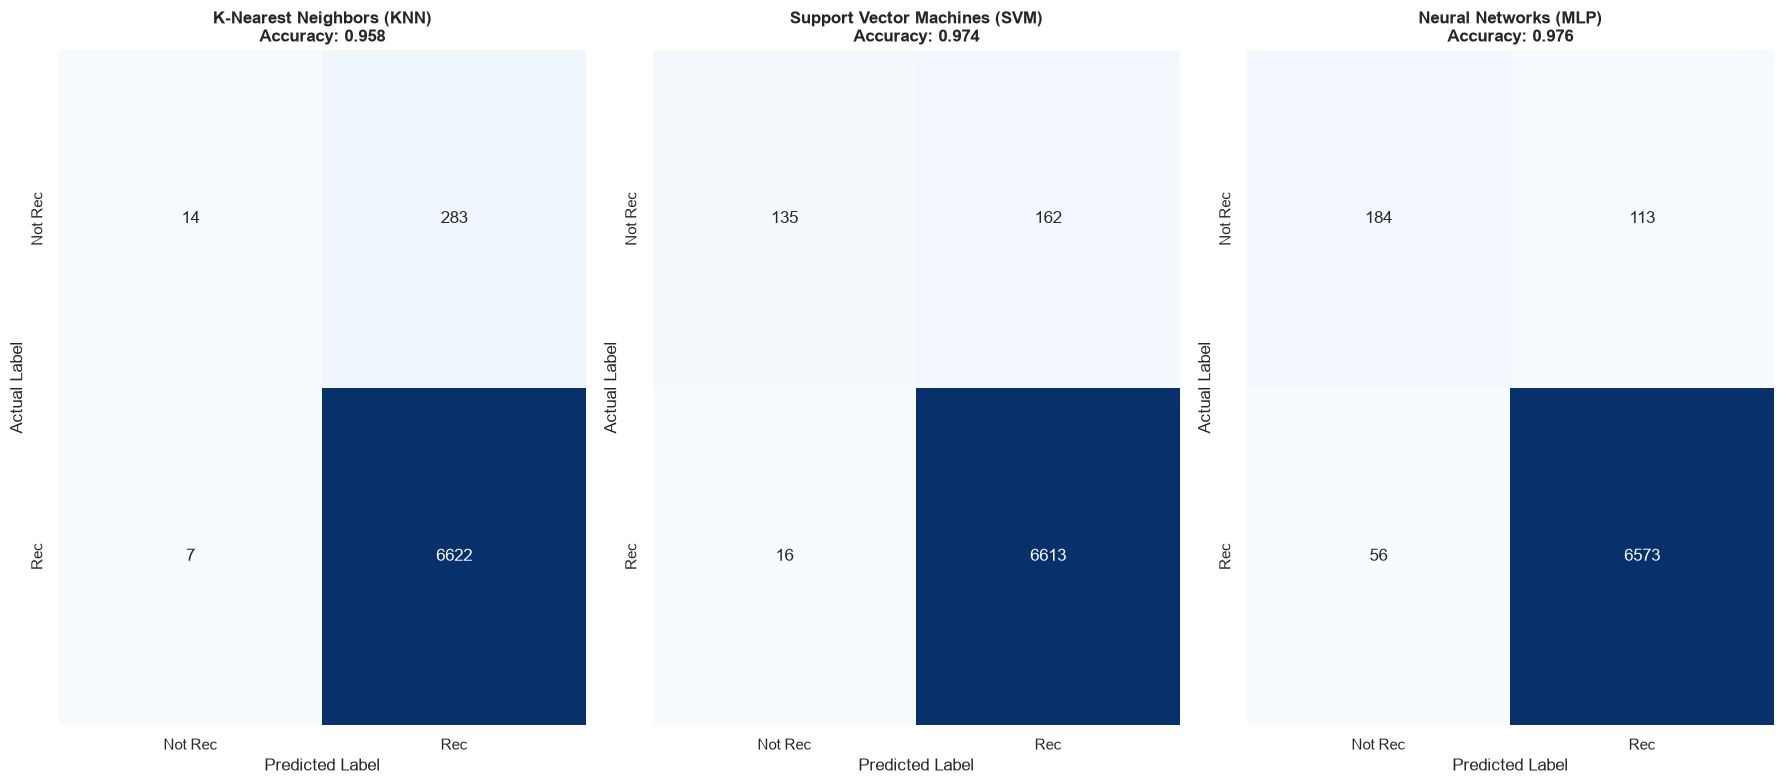

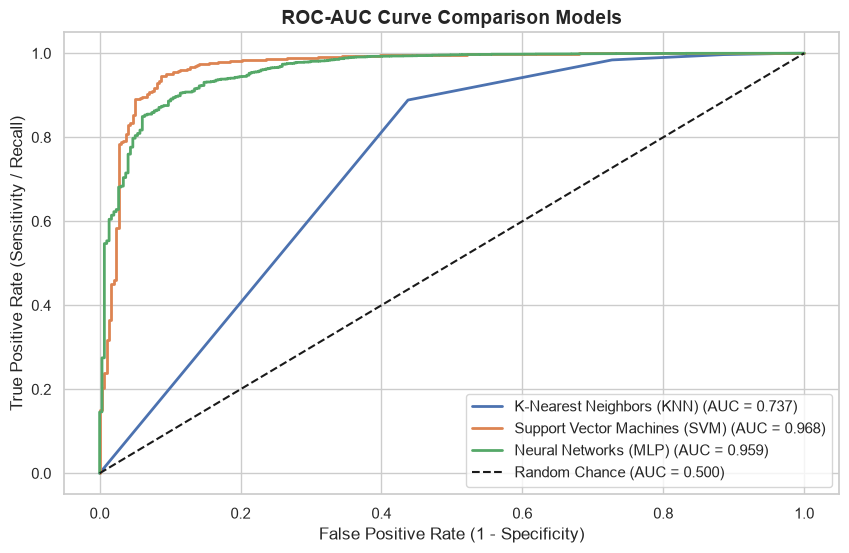

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

# Plot Confusion Matrices
for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}\nAccuracy: {res['accuracy']:.3f}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('Actual Label')
    axes[idx].set_xticklabels(['Not Rec', 'Rec'])
    axes[idx].set_yticklabels(['Not Rec', 'Rec'])

plt.tight_layout()
plt.show()

# Plot Comparative ROC-AUC Curves
plt.figure(figsize=(10, 6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['roc_auc']:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.500)')
plt.title('ROC-AUC Curve Comparison Models', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.legend(loc='lower right')
plt.show()